# Inferencia bayesiana conjunta de $\beta$ y $\sigma$
## Metropolis–Hastings con caminata aleatoria en dos dimensiones

**Clase práctica · 6 de noviembre de 2026**

Ahora aprendemos simultáneamente la transmisión y la variabilidad de las observaciones:

$$p(\beta,\sigma\mid\mathbf y).$$



Requiere `numpy`, `scipy`, `matplotlib` e `IPython`. Ejecuta las celdas en orden.


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid, cumulative_trapezoid
from scipy.stats import lognorm
from IPython.display import display, Markdown

plt.rcParams.update({'figure.figsize': (10, 4.5), 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, ORO, ROJO = '#003D79', '#D59F0F', '#D65F4A'


## 1. Del parámetro a los datos

$$
\beta\longrightarrow (S,I,R)\longrightarrow G_j(\beta)\longrightarrow Y_j.
$$

Fijamos $N=1000$, $I(0)=10$, $R(0)=0$ y $\gamma=0.25$ por día, siguiendo **el código** de la clase 2. Inferimos $\beta$ y la desviación estándar del error $\sigma$.

Los datos representan infecciones nuevas por día, no las personas actualmente infecciosas:

$$
G_j(\beta)=S(j-1;\beta)-S(j;\beta).
$$

Resolviendo en los extremos de cada día, `-np.diff(S)` obtiene esas diferencias. No usamos $I(t)$ como predicción de casos diarios.


In [19]:
N = 1000
I0, R_init = 10, 0
S0 = N - I0 - R_init
y0 = [S0, I0, R_init]
gamma = 0.25
m = 28                         # días que usamos para inferir beta
horizonte = 60                 # observaciones futuras reservadas

def sir(t, y, beta):
    S, I, R = y
    infecciones = beta * S * I / N
    recuperaciones = gamma * I
    return [-infecciones, infecciones - recuperaciones, recuperaciones]

def incidencia(beta, dias=m):
    """Incidencia en los intervalos (0,1], ..., (dias-1,dias]."""
    sol = solve_ivp(sir, [0, dias], y0, args=(beta,),
                    t_eval=np.arange(dias + 1), rtol=1e-7, atol=1e-9)
    if not sol.success:
        raise RuntimeError(sol.message)
    return -np.diff(sol.y[0])


## 2. Un laboratorio reproducible

Generamos observaciones sintéticas con $\beta_{\mathrm{real}}=0.40$ y

$$
Y_j=G_j(\beta_{\mathrm{real}})+\varepsilon_j,
\qquad \varepsilon_j\overset{\mathrm{ind}}{\sim}\mathcal N(0,2.5^2).
$$


- La normal admite valores negativos y decimales; es una aproximación didáctica, no un modelo literal de conteos.

- Para recuentos reales discutiríamos Poisson o binomial negativa.

- Reservamos los días posteriores al 28: no intervienen en el ajuste, la estimación del error ni el muestreo posterior. El valor real se usa sólo para generar datos y evaluar el ejercicio.


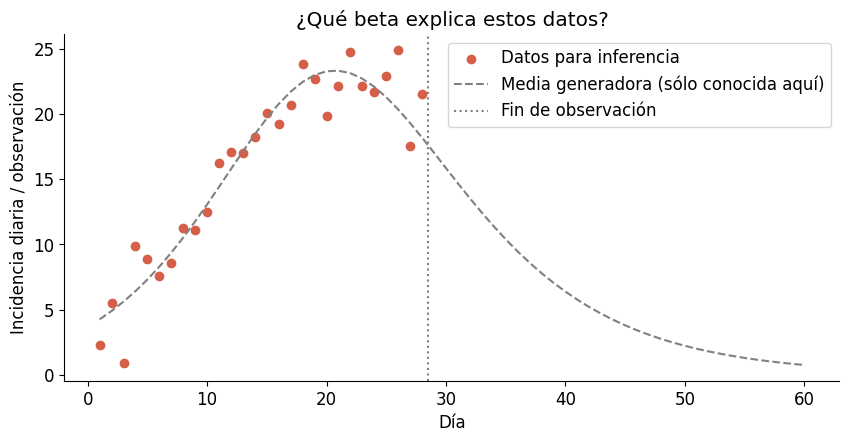

In [20]:
rng_datos = np.random.default_rng(2026)
beta_real = 0.40
sigma_generador = 2.5
media_real = incidencia(beta_real, horizonte)
y_todos = media_real + rng_datos.normal(0, sigma_generador, horizonte)
y_obs = y_todos[:m].copy()
dias = np.arange(1, horizonte + 1)

fig, ax = plt.subplots()
ax.scatter(dias[:m], y_obs, color=ROJO, label='Datos para inferencia')
ax.plot(dias, media_real, '--', color='gray', label='Media generadora (sólo conocida aquí)')
ax.axvline(m + 0.5, color='gray', linestyle=':', label='Fin de observación')
ax.set(xlabel='Día', ylabel='Incidencia diaria / observación', title='¿Qué beta explica estos datos?')
ax.legend()
plt.show()


## 3. Dos incógnitas, dos distribuciones a priori

- $\beta$ controla la curva de incidencia media; $\sigma$ controla la dispersión de las observaciones alrededor de esa curva.

- Ambas cantidades son positivas y tienen unidades diferentes: $\beta$ se expresa por día y $\sigma$ en la escala de la observación diaria.

- Elegimos, de forma ilustrativa:

$$
\log\beta\sim\mathcal N(\log(0.35),0.35^2),\qquad
\log\sigma\sim\mathcal N(\log(3),0.7^2).
$$

Así, $p(\beta,\sigma)=p(\beta)p(\sigma)$.

- La independencia a priori no implica independencia posterior. La mediana prior de sigma es 3, con bastante dispersión; no procede de residuos ni del valor generador. Es una suposición que debemos examinar.

- La log-densidad lognormal respecto al parámetro positivo $x$ incluye $-\log x$. Caminaremos directamente en $(\beta,\sigma)$, no en sus logaritmos.


Intervalo prior central 90% de Beta: [0.19680913 0.62243047]
Intervalo prior central 90% de Sigma: [0.9485837  9.48782908]


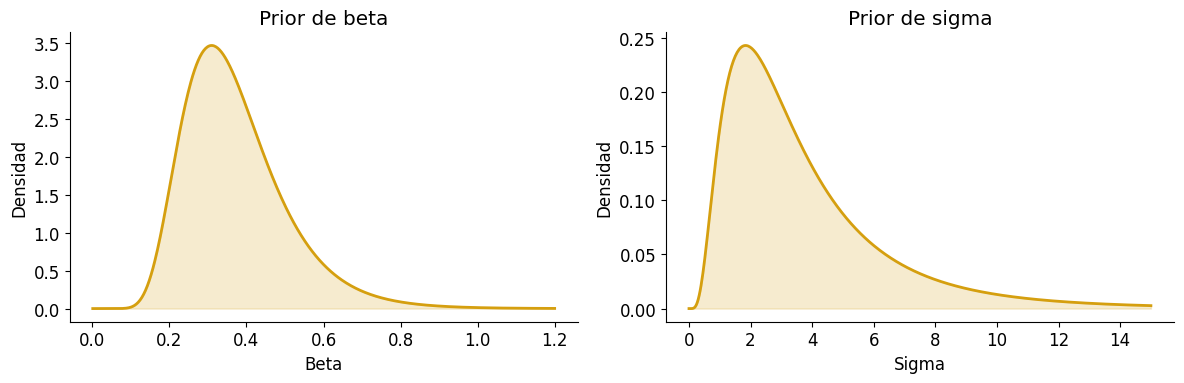

In [21]:
mu_beta, tau_beta = np.log(0.35), 0.35
mu_sigma, tau_sigma = np.log(3.0), 0.70

def log_lognormal(x, mu, tau):
    if not np.isfinite(x) or x <= 0:
        return -np.inf
    return -np.log(x*tau*np.sqrt(2*np.pi)) - 0.5*((np.log(x)-mu)/tau)**2

def log_prior(theta):
    beta, sigma = theta
    return (log_lognormal(beta, mu_beta, tau_beta)
            + log_lognormal(sigma, mu_sigma, tau_sigma))

prior_beta = lognorm(s=tau_beta, scale=np.exp(mu_beta))
prior_sigma = lognorm(s=tau_sigma, scale=np.exp(mu_sigma))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, prior, limite, nombre in zip(axs, [prior_beta, prior_sigma], [1.2, 15], ['Beta', 'Sigma']):
    x = np.linspace(0.001, limite, 500)
    ax.plot(x, prior.pdf(x), color=ORO, lw=2)
    ax.fill_between(x, prior.pdf(x), color=ORO, alpha=0.2)
    ax.set(xlabel=nombre, ylabel='Densidad', title=f'Prior de {nombre.lower()}')
    print(f'Intervalo prior central 90% de {nombre}:', prior.ppf([.05,.95]))
fig.tight_layout()
plt.show()


## 4. La verosimilitud también depende de sigma

$$
Y_j\mid\beta,\sigma\overset{\mathrm{ind}}{\sim}\mathcal N(G_j(\beta),\sigma^2).
$$

$$
\log L(\beta,\sigma)
=-m\log\sigma-\frac m2\log(2\pi)
-\frac{1}{2\sigma^2}\sum_{j=1}^m[y_j-G_j(\beta)]^2.
$$

 Aumentar sigma reduce la penalización de residuos, pero también dispersa la distribución y reduce su altura; ambos efectos están en la verosimilitud.

$$
\log\pi(\beta,\sigma)=\log L(\beta,\sigma)+\log p(\beta)+\log p(\sigma)+C.
$$


In [22]:
def log_verosimilitud(theta):
    beta, sigma = theta
    if beta <= 0 or sigma <= 0 or not np.all(np.isfinite(theta)):
        return -np.inf
    residuos = y_obs - incidencia(beta)
    return (-m*np.log(sigma) - 0.5*m*np.log(2*np.pi)- np.sum(residuos**2)/(2*sigma**2))

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_verosimilitud(theta)

for theta in [(0.30, 2.5), (0.40, 2.5), (0.40, 5.0)]:
    print(theta, 'log-posterior sin constante:', log_posterior(theta))

# Referencia numérica de la posterior conjunta para compararla con MH.
# Cada fila corresponde a un beta y cada columna a una sigma.
grid_beta = np.linspace(0.20, 0.60, 321)
grid_sigma = np.linspace(0.25, 10.0, 321)

# Resolver el SIR una vez por beta evita hacerlo por cada par de la cuadrícula.
suma_cuadrados_grid = np.array([
    np.sum((y_obs - incidencia(beta)) ** 2) for beta in grid_beta
])

log_prior_beta_grid = np.array([log_lognormal(beta, mu_beta, tau_beta)
                                for beta in grid_beta])
log_prior_sigma_grid = np.array([log_lognormal(sigma, mu_sigma, tau_sigma)
                                 for sigma in grid_sigma])
log_verosimilitud_grid = (
    -m * np.log(grid_sigma)[None, :] - 0.5 * m * np.log(2 * np.pi)
    - suma_cuadrados_grid[:, None] / (2 * grid_sigma[None, :] ** 2))
log_post_grid = (log_prior_beta_grid[:, None] + log_prior_sigma_grid[None, :] + log_verosimilitud_grid)


post_grid = np.exp(log_post_grid - log_post_grid.max())
post_grid /= trapezoid(trapezoid(post_grid, grid_sigma, axis=1), grid_beta)

marg_beta = trapezoid(post_grid, grid_sigma, axis=1)
marg_sigma = trapezoid(post_grid, grid_beta, axis=0)
media_beta_grid = trapezoid(grid_beta * marg_beta, grid_beta)
media_sigma_grid = trapezoid(grid_sigma * marg_sigma, grid_sigma)


(0.3, 2.5) log-posterior sin constante: -423.7485051760836
(0.4, 2.5) log-posterior sin constante: -60.62752834179064
(0.4, 5.0) log-posterior sin constante: -74.43387175297009


## 5. Algoritmo de Metropolis--Hastings en cinco pasos

Cada estado es $\theta=(\beta,\sigma)$. Denotemos por $\log\pi(\theta)$ la log-posterior sin su constante normalizadora. En el código esta cantidad se llama `log_posterior`.

1. **Inicializar.** Elegimos $\theta^{(0)}=(\beta^{(0)},\sigma^{(0)})$ dentro del soporte, con $\beta^{(0)}>0$ y $\sigma^{(0)}>0$, y evaluamos $\log\pi(\theta^{(0)})$.

2. **Proponer.** En la iteración $k$, generamos un candidato $\theta^*$ cerca del estado actual.

3. **Evaluar.** Calculamos $\log\pi(\theta^*)$. Si $\beta^*\leq0$ o $\sigma^*\leq0$, esta cantidad vale $-\infty$.

4. **Comparar.** Como la propuesta es simétrica, calculamos

$$
\log\alpha=\min\left\{0,\log\pi(\theta^*)-\log\pi(\theta^{(k)})\right\},
$$

y generamos $u\sim\mathrm{Uniforme}(0,1)$.

5. **Aceptar o rechazar.** Si $\log u<\log\alpha$, guardamos $\theta^{(k+1)}=\theta^*$. Si no, repetimos el estado actual: $\theta^{(k+1)}=\theta^{(k)}$.

Repetimos los pasos 2--5. El índice $k$ cuenta iteraciones del algoritmo, no días de la epidemia.

Para este ejemplo proponemos simultáneamente

$$
\beta^*=\beta+s_\beta Z_1,\qquad
\sigma^*=\sigma+s_\sigma Z_2,\qquad Z_1,Z_2\overset{\mathrm{ind}}{\sim}\mathcal N(0,1).
$$

Usamos escalas diferentes porque los parámetros tienen escalas distintas. Aceptamos o rechazamos **el par completo**. El normalizador de la posterior no se necesita porque se cancela al comparar ambos estados.


In [23]:
def metropolis_hastings_2d(log_objetivo, inicio, pasos, n_iter, semilla):
    rng = np.random.default_rng(semilla)
    actual = np.array(inicio, dtype=float)
    pasos = np.asarray(pasos)
    log_actual = log_objetivo(actual)
    if not np.isfinite(log_actual):
        raise ValueError('Inicio fuera del soporte.')
    cadena = np.empty((n_iter, 2))
    propuestas = np.empty_like(cadena)
    aceptadas = np.zeros(n_iter, dtype=bool)
    for k in range(n_iter):
        candidata = actual + pasos*rng.normal(size=2)
        log_candidata = log_objetivo(candidata)
        log_alpha = min(0.0, log_candidata-log_actual)
        if np.log(rng.uniform()) < log_alpha:
            actual = candidata
            log_actual = log_candidata
            aceptadas[k] = True
        cadena[k] = actual                 # repetimos el par si rechazamos
        propuestas[k] = candidata
    return cadena, propuestas, aceptadas


## 6. Tres cadenas, sin ajuste previo de sigma

- Elegimos inicios y escalas ilustrativos antes del muestreo.

- No hay optimización ni estimación por residuos.

- El calentamiento se excluye de los resúmenes. Su longitud fija no garantiza convergencia: compararemos tres cadenas, autocorrelaciones y la referencia numérica.


In [24]:
n_iter, calentamiento = 9000, 2000
#pasos = [0.007, 0.45]
pasos = [0.007, 0.45]
inicios = [[0.25, 1.0], [0.40, 3.0], [0.60, 6.0]]
resultados = [metropolis_hastings_2d(log_posterior, inicio, pasos, n_iter, 400+i)
              for i, inicio in enumerate(inicios)]
cadenas = np.array([r[0] for r in resultados])
retenidas = cadenas[:, calentamiento:, :]
muestras = retenidas.reshape(-1, 2)
for i, r in enumerate(resultados):
    print(f'Cadena {i+1}: aceptación posterior al calentamiento {r[2][calentamiento:].mean():.1%}')


Cadena 1: aceptación posterior al calentamiento 26.2%
Cadena 2: aceptación posterior al calentamiento 26.2%
Cadena 3: aceptación posterior al calentamiento 25.9%


## 7. Dibujos del recorrido

Las trazas muestran ambos parámetros. El panel del plano muestra 100 estados posteriores al calentamiento: los segmentos unen estados consecutivos y las cruces indican propuestas rechazadas. Una propuesta rechazada no altera la posición.


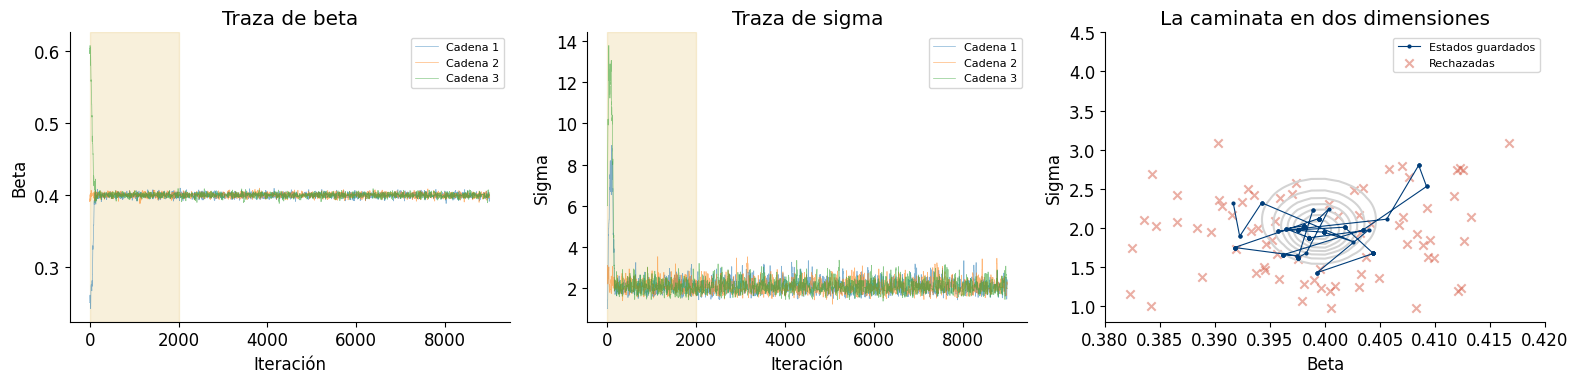

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for j, nombre in enumerate(['Beta', 'Sigma']):
    for i, c in enumerate(cadenas):
        axs[j].plot(c[:,j], alpha=.55, lw=.5, label=f'Cadena {i+1}')
    axs[j].axvspan(0, calentamiento, color=ORO, alpha=.15)
    axs[j].set(xlabel='Iteración', ylabel=nombre, title=f'Traza de {nombre.lower()}')
    axs[j].legend(fontsize=8)
c, propuestas, aceptadas = resultados[0]
idx = np.arange(calentamiento, calentamiento+100)
axs[2].contour(grid_beta, grid_sigma, post_grid.T, levels=7, colors='lightgray')
axs[2].plot(c[idx,0], c[idx,1], '-o', ms=2, lw=.8, color=AZUL, label='Estados guardados')
r = idx[~aceptadas[idx]]
axs[2].scatter(propuestas[r,0], propuestas[r,1], marker='x', color=ROJO, alpha=.5, label='Rechazadas')
axs[2].set(xlabel='Beta', ylabel='Sigma', xlim=(.38,.42), ylim=(.8,4.5), title='La caminata en dos dimensiones')
axs[2].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 8. ¿Qué distribución visitó la cadena?

Comparamos histogramas y nube de puntos con la cuadrícula. En la nube cada punto es un par posterior: para predecir después conservaremos estos pares, en vez de mezclar beta y sigma por separado.

La autocorrelación recuerda que 21 000 estados retenidos no equivalen a 21 000 muestras independientes. Una aceptación muy alta por sí sola tampoco garantiza buena exploración.

### Autocorrelación de una cadena

Para una de las coordenadas de una cadena retenida, escribimos sus valores como $x_0,\ldots,x_{n-1}$ y los centramos: $z_i=x_i-\bar{x}$. Para un retardo $k$, la función `autocorrelacion` calcula

$$
\widehat\rho(k)=\frac{\sum_{i=0}^{n-k-1}z_i z_{i+k}}{\sum_{i=0}^{n-1}z_i^2}.
$$

El numerador compara cada estado con el que está $k$ iteraciones después; el denominador escala el resultado. Por construcción, $\widehat\rho(0)=1$. En el código, `max_lag=80` significa que sólo se muestran los primeros 80 retardos.

Una autocorrelación grande y positiva para retardos pequeños indica que los estados consecutivos son muy parecidos: la cadena se mueve lentamente y aporta menos información independiente. Es deseable que la curva baje hacia cero relativamente pronto. Esto es un diagnóstico de mezcla, no una prueba definitiva de convergencia.


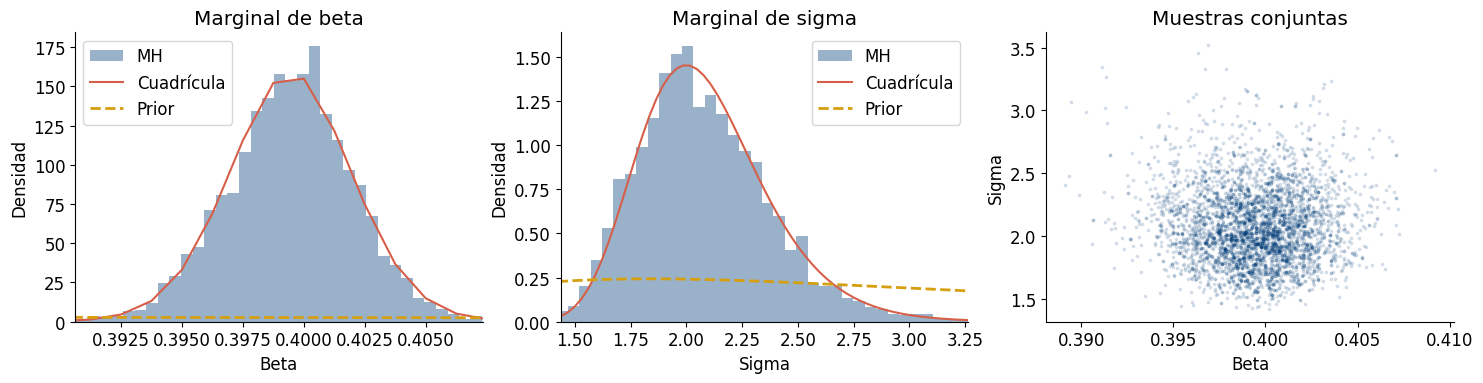

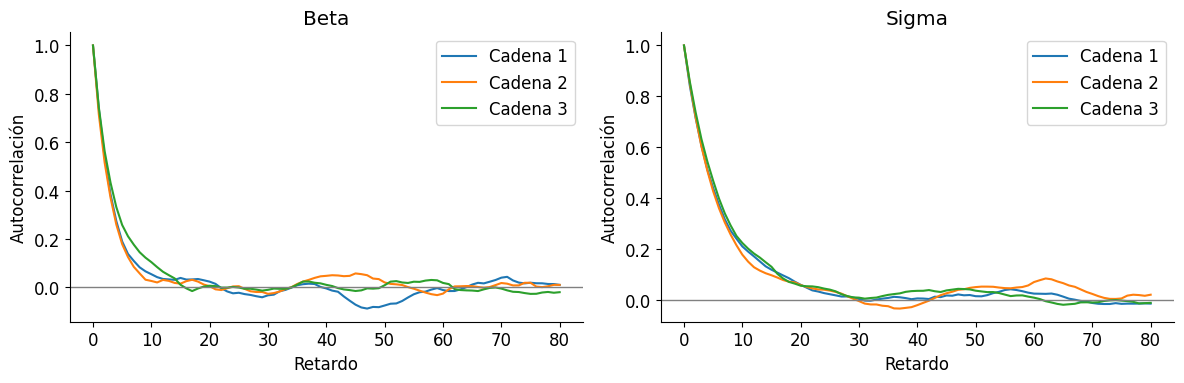

Cadena 1: medias beta y sigma = [0.39941884 2.07352545]
Cadena 2: medias beta y sigma = [0.39943605 2.07781435]
Cadena 3: medias beta y sigma = [0.3994624  2.08712064]
Medias de referencia en cuadrícula: 0.39945394458584116 2.092390507538268


In [29]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for j, (grid, densidad, prior, nombre) in enumerate([(grid_beta, marg_beta, prior_beta, 'Beta'),
                                                     (grid_sigma, marg_sigma, prior_sigma, 'Sigma')]):
    axs[j].hist(muestras[:,j], bins=45, density=True, alpha=.4, color=AZUL, label='MH')
    axs[j].plot(grid, densidad, color=ROJO, label='Cuadrícula')
    axs[j].plot(grid, prior.pdf(grid), color=ORO, ls='--', lw=2, label='Prior')
    q = np.quantile(muestras[:,j], [.001,.999])
    axs[j].set(xlim=(q[0],q[1]), xlabel=nombre, ylabel='Densidad', title=f'Marginal de {nombre.lower()}')
    axs[j].legend()
axs[2].scatter(muestras[::5,0], muestras[::5,1], s=3, alpha=.12, color=AZUL)
axs[2].set(xlabel='Beta', ylabel='Sigma', title='Muestras conjuntas')
fig.tight_layout()
plt.show()

def autocorrelacion(x, max_lag=80):
    z=x-x.mean()
    return np.array([np.dot(z[:len(z)-k],z[k:])/np.dot(z,z) for k in range(max_lag+1)])
fig, axs = plt.subplots(1,2,figsize=(12,4))
for j,nombre in enumerate(['Beta','Sigma']):
    for i,c in enumerate(retenidas):
        axs[j].plot(autocorrelacion(c[:,j]),label=f'Cadena {i+1}')
    axs[j].set(xlabel='Retardo',ylabel='Autocorrelación',title=nombre)
    axs[j].axhline(0,color='gray',lw=1); axs[j].legend()
fig.tight_layout()
plt.show()
for i,c in enumerate(retenidas):
    print(f'Cadena {i+1}: medias beta y sigma =', c.mean(axis=0))
print('Medias de referencia en cuadrícula:', media_beta_grid, media_sigma_grid)


## 9. Resultados e interpretación

Cada columna permite calcular la posterior marginal del parámetro correspondiente. El intervalo central del 90 % se obtiene con los percentiles 5 y 95. Los intervalos son marginales; su producto no constituye automáticamente una región conjunta del 90 %.

La incertidumbre sobre beta **ya integra** la incertidumbre sobre sigma. Los resultados siguen condicionando en $\gamma$, $N$, las condiciones iniciales y el modelo de observación. El valor real sólo es conocido porque este ejemplo es sintético.


In [27]:
for j,nombre in enumerate(['Beta','Sigma']):
    q = np.quantile(muestras[:,j],[.05,.5,.95])
    print(f'{nombre}: media={muestras[:,j].mean():.5f}; mediana={q[1]:.5f}; IC creíble 90%=[{q[0]:.5f}, {q[2]:.5f}]')
print('Valores generadores (no usados en la posterior):', beta_real, sigma_generador)
print('Proporción de muestras con R0 > 1:', np.mean(muestras[:,0] > gamma))
print('Correlación posterior beta-sigma:', np.corrcoef(muestras.T)[0,1])


Beta: media=0.39944; mediana=0.39949; IC creíble 90%=[0.39507, 0.40359]
Sigma: media=2.07949; mediana=2.04122; IC creíble 90%=[1.64848, 2.62149]
Valores generadores (no usados en la posterior): 0.4 2.5
Proporción de muestras con R0 > 1: 1.0
Correlación posterior beta-sigma: -0.01985275982302381


## 10. Predicciones con ambos parámetros desconocidos

Seleccionamos pares $(\beta^{(s)},\sigma^{(s)})$ de la posterior. Para cada par:

$$
G_j^{(s)}=G_j(\beta^{(s)}),\qquad
\widetilde Y_j^{(s)}\sim\mathcal N(G_j^{(s)},(\sigma^{(s)})^2).
$$

La banda de la media usa las curvas $G$; la predictiva agrega ruido con **la sigma de cada par**, no con una sigma fijada. Ambas bandas son puntuales por día. Las observaciones reservadas no participaron en la inferencia.


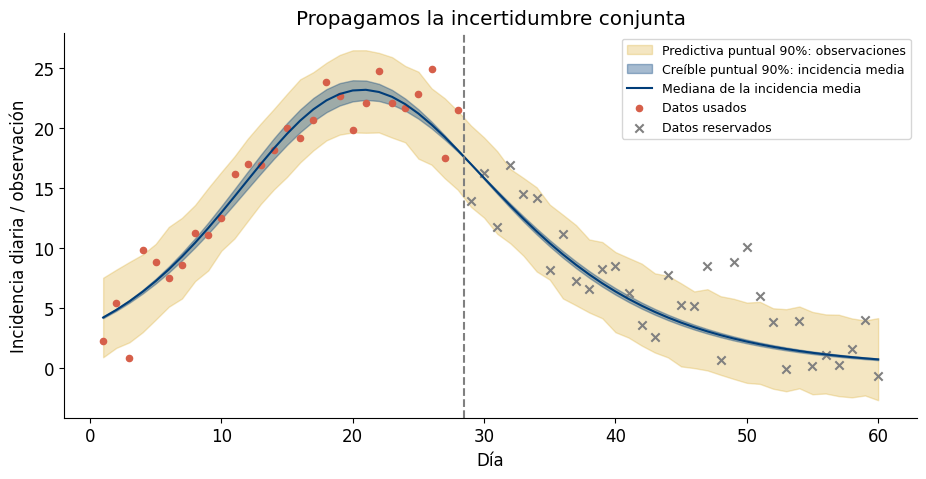

In [17]:
rng_pred = np.random.default_rng(77)
pares = muestras[rng_pred.choice(len(muestras),size=800,replace=False)]
curvas = np.array([incidencia(b,horizonte) for b,s in pares])
y_pred = curvas + rng_pred.normal(size=curvas.shape)*pares[:,1,None]
lo, med, hi = np.quantile(curvas,[.05,.5,.95],axis=0)
plo, phi = np.quantile(y_pred,[.05,.95],axis=0)
fig, ax = plt.subplots(figsize=(11,5))
ax.fill_between(dias,plo,phi,color=ORO,alpha=.25,label='Predictiva puntual 90%: observaciones')
ax.fill_between(dias,lo,hi,color=AZUL,alpha=.35,label='Creíble puntual 90%: incidencia media')
ax.plot(dias,med,color=AZUL,label='Mediana de la incidencia media')
ax.scatter(dias[:m],y_obs,color=ROJO,s=20,label='Datos usados')
ax.scatter(dias[m:],y_todos[m:],color='gray',marker='x',label='Datos reservados')
ax.axvline(m+.5,color='gray',ls='--')
ax.set(xlabel='Día',ylabel='Incidencia diaria / observación',title='Propagamos la incertidumbre conjunta')
ax.legend(fontsize=9)
plt.show()


## 11. Discusión y experimentos

1. Cambia sólo el paso de sigma a `0.02` y luego a `3.0`. Repite las cadenas y compara su exploración, no sólo la aceptación.
2. Cambia la mediana prior de sigma a 1 o 6 y observa cuánto cambian sus marginales. Mantén los mismos datos.
3. Usa siete días en lugar de 28 (cambia `m` y ejecuta desde el principio). ¿Qué parámetro se vuelve más incierto? Ajusta los límites de los gráficos si hace falta.


